## Figure 3 — Training Dynamics of the Prior Direction (Pythia)

For log-uniformly sampled Pythia checkpoints (410M / 1B / 2.8B), fit the
optimal-prior direction $d^*$ to the output (and input) embeddings and track:

- **(a) Prior recovery** — normalized KL divergence of the 1-D fitted prior
  vs the empirical Pile unigram distribution (uniform baseline = 1).
- **(b) Spectral prominence** — normalized rank of the variance along $d^*$
  among PCA eigenvalues; the "random direction rank" band shows the
  step-0 harmonic-mean null across model sizes (appendix note below).

Per-model curves are cached to `data/training_dynamics/*.npz`; the figure
cells only read the caches.


In [1]:
import os

import io
import json
import pickle
import sys
import zipfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import requests
import torch
import matplotlib.pyplot as plt
import ipywidgets as widgets

from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import (
    HfApi,
    hf_hub_download,
    hf_hub_url,
    list_repo_files,
    list_repo_refs,
)
from huggingface_hub.utils import build_hf_headers

# Self-contained layout: direction_of_ignorance/{scripts, data, notebook_plotters}
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebook_plotters" else cwd
SCRIPTS_DIR = ROOT / "scripts"
DATA_DIR = ROOT / "data"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils
from hallucination_utils import (
    empirical_logprior_from_counts,
    empirical_prob_from_counts_for_fit,
    empirical_token_counts,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# ── Configuration: empirical token-frequency prior (Pile) ───────────────────
coverage = 0.7
LLM_vocab_coverage = 0.5
count_threshold = 3
KL_fine_fitting = False
KL_fine_learning_rate = 0.05
KL_fine_steps = 250
KL_fine_plot_loss_curves = False
# Off: skip the per-snapshot PCA eigendecomposition, the harmonic-mean null,
# and the shuffled-label null (only needed for the spectral-rank panel);
# caches then hold NaN rank slots and are flagged stale if this is re-enabled.
plot_rank_fraction = False
EMPIRICAL_DATASET_NAME = "monology/pile-uncopyrighted"
EMPIRICAL_DATASET_CONFIG = None
EMPIRICAL_SPLIT = "train"
EMPIRICAL_TEXT_COLUMN = "text"
EMPIRICAL_CACHE_DIR = DATA_DIR / "token_stats"


In [3]:
# ── Outer loop: training-dynamics curves for all three Pythia models ─────────
# For each model: load log-uniform checkpoints -> PCA per snapshot ->
# normalized KL + spectral rank of d* -> shuffled-label null -> cache to npz.
# Cached models are skipped; the figure cell below overlays the caches.

figure_models = [
    # "EleutherAI/pythia-70m",
    # "EleutherAI/pythia-160m",
    "EleutherAI/pythia-410m",
    "EleutherAI/pythia-1b",
    "EleutherAI/pythia-1.4b",
    "EleutherAI/pythia-2.8b",
    "EleutherAI/pythia-6.9b",
]
force_recompute_dynamics = False
num_snapshots = 30
fitted_null_samples = 200

# Keep KL-fine-fitted caches separate so disabling fine fitting reuses the
# original linear-regression caches without recomputation.
dyn_cache_dir = DATA_DIR / (
    "training_dynamics_klfine" if KL_fine_fitting else "training_dynamics"
)
dyn_cache_dir.mkdir(parents=True, exist_ok=True)
kl_history_dir = dyn_cache_dir / "kl_fine_histories"
kl_history_dir.mkdir(parents=True, exist_ok=True)


def harmonic_mean_rank_fraction(eigvals):
    """Rank fraction of the spectrum's harmonic mean.

    A least-squares direction fit to labels independent of W has PC weights
    w_k ∝ g_k²/λ_k, so its Rayleigh quotient concentrates at the harmonic mean
    of the eigenvalues. Its expected normalized spectral rank is therefore the
    fraction of eigenvalues above the harmonic mean (appendix derivation).
    """
    lam = np.asarray(eigvals, dtype=np.float64)
    lam = lam[lam > 0]
    hm = lam.size / np.sum(1.0 / lam)
    return float(np.mean(lam > hm))


kl_fine_fit_histories = []


def fine_fit_prior_vector(W_fit, p_fit, d_prior_init, *, label=None):
    """Minimize CE(p_emp, softmax(W d_prior)) over one unconstrained vector."""
    fit_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    W_tensor = torch.as_tensor(W_fit, dtype=torch.float32, device=fit_device)
    p_tensor = torch.as_tensor(p_fit, dtype=torch.float32, device=fit_device)
    d_prior = torch.nn.Parameter(
        torch.as_tensor(d_prior_init, dtype=torch.float32, device=fit_device).clone()
    )
    optimizer = torch.optim.Adam([d_prior], lr=KL_fine_learning_rate)

    def cross_entropy_loss():
        logits = W_tensor @ d_prior
        return torch.logsumexp(logits, dim=0) - torch.dot(p_tensor, logits)

    with torch.no_grad():
        loss_curve = [float(cross_entropy_loss().cpu())]
    for _ in range(KL_fine_steps):
        optimizer.zero_grad(set_to_none=True)
        loss = cross_entropy_loss()
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite KL fine-fit loss for {label or 'snapshot'}.")
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            loss_curve.append(float(cross_entropy_loss().cpu()))

    empirical_entropy = float(-np.sum(p_fit * np.log(p_fit)))
    kl_curve = np.asarray(loss_curve, dtype=np.float64) - empirical_entropy
    d_prior_np = d_prior.detach().cpu().numpy().astype(np.float64)
    beta_star = float(np.linalg.norm(d_prior_np))
    if not np.isfinite(beta_star) or beta_star <= 0:
        raise FloatingPointError(f"Invalid fine-fit prior norm for {label or 'snapshot'}.")
    d_star = d_prior_np / beta_star

    print(
        f"KL fine fit{f' [{label}]' if label else ''}: "
        f"{kl_curve[0]:.6g} -> {kl_curve[-1]:.6g} "
        f"(CE {loss_curve[0]:.6g} -> {loss_curve[-1]:.6g})"
    )
    if label is not None:
        record = {
            "label": label,
            "cross_entropy": np.asarray(loss_curve, dtype=np.float64),
            "kl": kl_curve,
        }
        kl_fine_fit_histories.append(record)
        history_path = kl_history_dir / f"{label.replace(' ', '_')}.npz"
        np.savez_compressed(
            history_path,
            **record,
            coverage=float(coverage),
            min_count=int(count_threshold),
            learning_rate=float(KL_fine_learning_rate),
            optimization_steps=int(KL_fine_steps),
        )

    del optimizer, d_prior, W_tensor, p_tensor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return d_star, beta_star, kl_curve


def compute_snapshot_metrics(W_np, p_emp, *, fit_label=None, apply_kl_fine=None,
                             compute_rank=None):
    """Return normalized KL and spectral rank for one embedding snapshot.

    With ``compute_rank=False`` (default: the ``plot_rank_fraction`` flag) the
    PCA eigendecomposition is skipped entirely -- it is only needed for the
    spectral-rank appendix panel -- and the rank slots return NaN/None.
    """
    fit_mask_m = p_emp > 0
    W_fit = W_np[fit_mask_m]
    p_fit = p_emp[fit_mask_m]
    p_fit = p_fit / p_fit.sum()

    optimal_result = utils.frequency_dipole(
        W_np, p_emp, method="optimal_prior", exclude_zeros=True,
    )
    d_star = np.asarray(optimal_result["d_star"], dtype=np.float64)
    beta_star = float(optimal_result["beta_star"])
    kl_to_uniform = float(optimal_result["kl_to_uniform"])
    nkl = float(optimal_result["nkl"])

    if apply_kl_fine is None:
        apply_kl_fine = KL_fine_fitting
    if apply_kl_fine:
        d_prior_init = beta_star * d_star
        d_star, beta_star, kl_curve = fine_fit_prior_vector(
            W_fit,
            p_fit,
            d_prior_init,
            label=fit_label,
        )
        nkl = float(kl_curve[-1] / kl_to_uniform) if kl_to_uniform > 0 else np.nan

    if compute_rank is None:
        compute_rank = plot_rank_fraction
    if not compute_rank:
        return nkl, np.nan, None, None

    # PCA of this snapshot alone (vocab x 1 x hidden).
    pcs_list, eigs_list, _ = utils.layered_PCA(
        W_np[:, None, :], center=True, fixed_basis_at_layer=None, GPU=True,
    )
    eigvals = np.asarray(eigs_list[0], dtype=np.float64)
    pcs = np.asarray(pcs_list[0], dtype=np.float64)

    d_unit = d_star / np.linalg.norm(d_star).clip(min=1e-12)
    pc_weights = (pcs.T @ d_unit) ** 2
    lambda_d = float(np.sum(eigvals * pc_weights))
    rank = int(1 + np.sum(eigvals > lambda_d))
    return nkl, rank, eigvals, pcs


def fitted_null_rank_fractions(init_W, init_eigs, init_pcs, p_emp, n_samples, seed=0):
    """Shuffled-label fitted null at initialization, as rank fractions."""
    rng = np.random.default_rng(seed)
    fit_mask_m = p_emp > 0
    W_fit = np.asarray(init_W, dtype=np.float64)[fit_mask_m]
    p_fit = p_emp[fit_mask_m]
    p_fit = p_fit / p_fit.sum()
    W_tilde = W_fit - W_fit.mean(axis=0, keepdims=True)
    ell = np.log(p_fit)
    ell = ell - ell.mean()
    gram = W_tilde.T @ W_tilde
    ridge = 1e-4 * float(np.trace(gram)) / max(W_tilde.shape[1], 1)

    shuffled_ells = np.stack([rng.permutation(ell) for _ in range(n_samples)], axis=1)
    null_coefs = np.linalg.solve(gram + ridge * np.eye(W_tilde.shape[1]), W_tilde.T @ shuffled_ells)
    null_norms = np.linalg.norm(null_coefs, axis=0)
    null_directions = null_coefs[:, null_norms > 0] / null_norms[null_norms > 0][None, :]
    null_pc_weights = (init_pcs.T @ null_directions) ** 2
    null_lambdas = init_eigs @ null_pc_weights
    null_ranks = 1 + np.sum(init_eigs[:, None] > null_lambdas[None, :], axis=0)
    return null_ranks / init_eigs.size


def _http_range(url, start, end):
    """Fetch one inclusive byte range and verify that the server honored it."""
    response = requests.get(
        url,
        headers={**build_hf_headers(), "Range": f"bytes={start}-{end}"},
        timeout=300,
    )
    response.raise_for_status()
    expected = end - start + 1
    if response.status_code != 206 or len(response.content) != expected:
        raise RuntimeError(
            f"Range request failed ({response.status_code}, "
            f"{len(response.content)} bytes; expected {expected})"
        )
    return response.content, response.headers.get("etag", "")


def load_remote_safetensor(model_name, commit, filename, tensor_name):
    """Download only one tensor's byte range from a remote safetensors file."""
    url = hf_hub_url(model_name, filename, revision=commit)
    raw_header_len, etag = _http_range(url, 0, 7)
    header_len = int.from_bytes(raw_header_len, "little")
    raw_header, _ = _http_range(url, 8, 7 + header_len)
    metadata = json.loads(raw_header.decode("utf-8"))
    if tensor_name not in metadata:
        raise KeyError(f"{tensor_name} not found in {filename}@{commit[:12]}")

    spec = metadata[tensor_name]
    rel_start, rel_end = spec["data_offsets"]
    data_start = 8 + header_len
    raw_tensor, _ = _http_range(
        url, data_start + rel_start, data_start + rel_end - 1,
    )
    shape = tuple(spec["shape"])
    dtype = spec["dtype"]
    numpy_dtypes = {
        "F16": np.float16,
        "F32": np.float32,
        "F64": np.float64,
    }
    if dtype in numpy_dtypes:
        array = np.frombuffer(raw_tensor, dtype=numpy_dtypes[dtype]).reshape(shape)
        array = array.astype(np.float64)
    elif dtype == "BF16":
        # NumPy has no portable bfloat16 dtype; decode through torch.
        array = (
            torch.frombuffer(bytearray(raw_tensor), dtype=torch.bfloat16)
            .reshape(shape)
            .to(torch.float64)
            .numpy()
        )
    else:
        raise TypeError(f"Unsupported embedding dtype {dtype} in {filename}")
    return array, etag


def checkpoint_weight_fingerprint(model_name, commit):
    """Stable identity of the weight blobs for one revision.

    Prefer sharded safetensors (revision-specific). Fall back to
    ``pytorch_model.bin``. Ignore the monolithic ``model.safetensors``: on
    pythia-2.8b many branches share one stale copy of it.
    """
    info = HfApi().repo_info(model_name, revision=commit, files_metadata=True)
    siblings = {f.rfilename: f for f in info.siblings}
    shards = []
    for name, meta in siblings.items():
        if (
            name.startswith("model-")
            and name.endswith(".safetensors")
            and getattr(meta, "lfs", None) is not None
        ):
            shards.append((name, meta.lfs.sha256))
    if shards:
        return ("shards", tuple(sorted(shards)))
    bin_shards = []
    for name, meta in siblings.items():
        if (
            name.startswith("pytorch_model-")
            and name.endswith(".bin")
            and getattr(meta, "lfs", None) is not None
        ):
            bin_shards.append((name, meta.lfs.sha256))
    if bin_shards:
        return ("bin_shards", tuple(sorted(bin_shards)))
    bin_meta = siblings.get("pytorch_model.bin")
    if bin_meta is not None and getattr(bin_meta, "lfs", None) is not None:
        return ("bin", bin_meta.lfs.sha256)
    return None


def usable_checkpoint_steps(model_name, step_to_commit):
    """Steps whose weight blobs are unique (or only shared by step 0/1).

    Corrupt pythia-2.8b branches that reuse another revision's weights are
    dropped; log-uniform sampling then snaps onto nearby usable checkpoints.
    """
    fingerprints = {
        step: checkpoint_weight_fingerprint(model_name, commit)
        for step, commit in step_to_commit.items()
    }
    owners = {}
    for step, fp in fingerprints.items():
        if fp is None:
            continue
        owners.setdefault(fp, []).append(step)
    usable = []
    for fp, steps in owners.items():
        steps = sorted(steps)
        if len(steps) == 1 or set(steps) == {0, 1}:
            usable.extend(steps)
    return sorted(set(usable))


def snap_log_uniform_steps(usable_steps, num_snapshots):
    """Log-uniformly sample ``num_snapshots`` points from usable checkpoints."""
    usable = sorted(usable_steps)
    if 0 not in usable:
        raise RuntimeError("usable checkpoints do not include step 0")
    nonzero = np.asarray([s for s in usable if s > 0], dtype=np.float64)
    if nonzero.size == 0:
        return [0]
    targets = np.geomspace(nonzero.min(), nonzero.max(), num_snapshots)
    snapped = {
        int(nonzero[np.argmin(np.abs(np.log(nonzero) - np.log(t)))])
        for t in targets
    }
    return sorted({0} | snapped)


class _RemoteRangeFile(io.RawIOBase):
    """Seekable HTTP Range reader for remote ZIP archives (``pytorch_model.bin``)."""

    def __init__(self, url, size):
        super().__init__()
        self.url = url
        self.size = int(size)
        self.pos = 0
        self._headers = build_hf_headers()

    def seekable(self):
        return True

    def readable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=0):
        if whence == 0:
            self.pos = offset
        elif whence == 1:
            self.pos += offset
        elif whence == 2:
            self.pos = self.size + offset
        else:
            raise ValueError(whence)
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        if n <= 0 or self.pos >= self.size:
            return b""
        end = min(self.pos + n, self.size) - 1
        response = requests.get(
            self.url,
            headers={**self._headers, "Range": f"bytes={self.pos}-{end}"},
            timeout=300,
        )
        response.raise_for_status()
        expected = end - self.pos + 1
        if response.status_code != 206 or len(response.content) != expected:
            raise RuntimeError(
                f"Range request failed ({response.status_code}, "
                f"{len(response.content)} bytes; expected {expected})"
            )
        self.pos = end + 1
        return response.content


def load_remote_pytorch_bin_embeddings(model_name, commit, weight_files):
    """Range-extract embedding storages from one or more PyTorch ZIP shards.

    ``weight_files`` maps tensor name to its monolithic or sharded `.bin` file.
    """
    info = HfApi().repo_info(model_name, revision=commit, files_metadata=True)
    file_sizes = {f.rfilename: f.size for f in info.siblings}

    @dataclass
    class _Storage:
        dtype: object
        key: str
        numel: int

    @dataclass
    class _Tensor:
        storage: _Storage
        offset: int
        size: tuple
        stride: tuple

    def _rebuild_tensor(storage, storage_offset, size, stride, *args):
        return _Tensor(storage, int(storage_offset), tuple(size), tuple(stride))

    def _rebuild_parameter(data, *args):
        return data

    class _TorchUnpickler(pickle.Unpickler):
        def find_class(self, module, name):
            if module == "torch._utils" and name.startswith("_rebuild_tensor"):
                return _rebuild_tensor
            if module == "torch._utils" and name == "_rebuild_parameter":
                return _rebuild_parameter
            if module == "torch" and name.endswith("Storage"):
                return name
            return super().find_class(module, name)

        def persistent_load(self, saved_id):
            typ, storage_type, key, location, numel = saved_id
            return _Storage(storage_type, key, numel)

    grouped = {}
    for tensor_name, filename in weight_files.items():
        grouped.setdefault(filename, []).append(tensor_name)

    arrays = {}
    source_ids = []
    for filename, tensor_names in grouped.items():
        if filename not in file_sizes:
            raise FileNotFoundError(f"{filename} absent at {model_name}@{commit[:12]}")
        remote = _RemoteRangeFile(
            hf_hub_url(model_name, filename, revision=commit),
            file_sizes[filename],
        )
        with zipfile.ZipFile(remote) as archive:
            data_pkl = next(
                name for name in archive.namelist() if name.endswith("/data.pkl")
            )
            archive_root = data_pkl.rsplit("/", 1)[0]
            state = _TorchUnpickler(
                io.BytesIO(archive.read(data_pkl))
            ).load()
            for tensor_name in tensor_names:
                tensor = state[tensor_name]
                if tensor.offset != 0:
                    raise ValueError(f"{tensor_name} has nonzero storage offset")
                if tensor.storage.dtype != "HalfStorage":
                    raise TypeError(
                        f"{tensor_name} uses unsupported {tensor.storage.dtype}"
                    )
                raw = archive.read(
                    f"{archive_root}/data/{tensor.storage.key}"
                )
                count = int(np.prod(tensor.size))
                expected = count * np.dtype(np.float16).itemsize
                if len(raw) < expected:
                    raise ValueError(
                        f"{tensor_name}: storage {tensor.storage.key} too small "
                        f"({len(raw)} < {expected})"
                    )
                arrays[tensor_name] = (
                    np.frombuffer(raw, dtype=np.float16, count=count)
                    .reshape(tensor.size)
                    .astype(np.float64)
                )
                source_ids.append((filename, tensor.storage.key))
    return (
        arrays["embed_out.weight"],
        arrays["gpt_neox.embed_in.weight"],
        ("bin", commit, tuple(sorted(source_ids))),
    )


def load_revision_embeddings(model_name, commit):
    """Load only the input/output embeddings for one training checkpoint.

    Prefer revision-specific sharded safetensors. If those are absent (common
    on late pythia-2.8b branches), extract the same tensors from the unique
    ``pytorch_model.bin`` via ZIP byte ranges. Never load the shared stale
    monolithic ``model.safetensors``.
    """
    files = set(list_repo_files(model_name, revision=commit))
    index_name = "model.safetensors.index.json"
    keys = ("embed_out.weight", "gpt_neox.embed_in.weight")

    if index_name in files:
        index_path = hf_hub_download(model_name, index_name, revision=commit)
        with open(index_path) as f:
            weight_map = json.load(f)["weight_map"]
        missing = [key for key in keys if key not in weight_map]
        if missing:
            raise KeyError(f"{model_name}@{commit[:12]} missing indexed weights {missing}")
        arrays, etags = [], []
        for key in keys:
            array, etag = load_remote_safetensor(
                model_name, commit, weight_map[key], key,
            )
            arrays.append(array)
            etags.append(etag)
        return arrays[0], arrays[1], ("shards",) + tuple(etags)

    bin_index_name = "pytorch_model.bin.index.json"
    if bin_index_name in files:
        index_path = hf_hub_download(
            model_name, bin_index_name, revision=commit,
        )
        with open(index_path) as f:
            bin_weight_map = json.load(f)["weight_map"]
        missing = [key for key in keys if key not in bin_weight_map]
        if missing:
            raise KeyError(
                f"{model_name}@{commit[:12]} missing indexed bin weights {missing}"
            )
        return load_remote_pytorch_bin_embeddings(
            model_name,
            commit,
            {key: bin_weight_map[key] for key in keys},
        )

    if "pytorch_model.bin" in files:
        return load_remote_pytorch_bin_embeddings(
            model_name,
            commit,
            {key: "pytorch_model.bin" for key in keys},
        )

    raise FileNotFoundError(
        f"{model_name}@{commit[:12]} has neither indexed safetensors "
        f"nor indexed/monolithic PyTorch bins"
    )


CHECKPOINT_SOURCE_TAG = "unique_revision_embeddings_v1"


def kl_fit_cache_matches(cache):
    """Whether a cache was produced with the requested KL fine-fit settings."""
    required = {"kl_fine_fitting", "kl_fine_learning_rate", "kl_fine_steps"}
    if not required.issubset(cache.files):
        # Legacy caches predate KL fine fitting and contain the original linear fit.
        return not KL_fine_fitting
    if bool(cache["kl_fine_fitting"]) != bool(KL_fine_fitting):
        return False
    if not KL_fine_fitting:
        return True
    return (
        np.isclose(
            float(cache["kl_fine_learning_rate"]),
            float(KL_fine_learning_rate),
            rtol=0.0,
            atol=1e-12,
        )
        and int(cache["kl_fine_steps"]) == int(KL_fine_steps)
    )


def write_dynamics_cache(
    cache_path,
    *,
    recorded_steps,
    nkl_curve,
    rank_curve,
    nkl_curve_in,
    rank_curve_in,
    d_model,
    hm_init,
    hm_init_in,
    coverage,
    min_count,
    null_stats=None,
    cache_complete=False,
):
    """Rewrite the per-model npz after every checkpoint (resume-safe)."""
    payload = dict(
        steps=np.asarray(recorded_steps, dtype=np.int64),
        cache_complete=bool(cache_complete),
        # False when any snapshot skipped the PCA/rank pipeline
        # (plot_rank_fraction off): its rank slot holds NaN and the cache is
        # stale for rank plotting.
        rank_computed=bool(
            np.all(np.isfinite(np.asarray(rank_curve, dtype=np.float64)))
            and np.all(np.isfinite(np.asarray(rank_curve_in, dtype=np.float64)))
        ),
        d_model=int(d_model),
        checkpoint_source=CHECKPOINT_SOURCE_TAG,
        coverage=float(coverage),
        min_count=int(min_count),
        kl_fine_fitting=bool(KL_fine_fitting),
        kl_fine_learning_rate=float(KL_fine_learning_rate),
        kl_fine_steps=int(KL_fine_steps),
        nkl=np.asarray(nkl_curve, dtype=np.float64),
        rayleigh_rank=np.asarray(rank_curve, dtype=np.float64),
        rank_fraction=np.asarray(rank_curve, dtype=np.float64) / d_model,
        hm_rank_fraction=float(np.nan if hm_init is None else hm_init),
        hm_rank_fraction_in=float(np.nan if hm_init_in is None else hm_init_in),
        nkl_in=np.asarray(nkl_curve_in, dtype=np.float64),
        rayleigh_rank_in=np.asarray(rank_curve_in, dtype=np.float64),
        rank_fraction_in=np.asarray(rank_curve_in, dtype=np.float64) / d_model,
    )
    if null_stats is not None:
        payload.update(null_stats)
    np.savez(cache_path, **payload)


for loop_model_name in figure_models:
    model_tag = loop_model_name.split("/")[-1]
    cache_path = dyn_cache_dir / f"{model_tag}.npz"

    # Complete caches must bypass *all* Hub access. Legacy small-model caches
    # predate source tagging and are accepted; integrity-checked large-model
    # caches must carry the current verified source tag.
    integrity_checked_models = {"pythia-2.8b", "pythia-6.9b"}
    if cache_path.exists() and not force_recompute_dynamics:
        with np.load(cache_path) as _c:
            required = {
                "steps", "d_model", "nkl", "nkl_in", "coverage", "min_count",
            }
            if plot_rank_fraction:
                # Rank plotting needs the spectral metrics and the shuffled
                # -label null; a cache produced with the rank pipeline off
                # carries NaN placeholders and must be recomputed.
                required |= {
                    "rayleigh_rank", "rank_fraction",
                    "rayleigh_rank_in", "rank_fraction_in",
                    "hm_rank_fraction", "hm_rank_fraction_in",
                    "null_frac_mean", "null_frac_lo", "null_frac_hi",
                    "null_frac_mean_in", "null_frac_lo_in", "null_frac_hi_in",
                }
            complete = required.issubset(_c.files)
            rank_ok = not plot_rank_fraction or (
                "rank_computed" not in _c.files  # legacy caches computed ranks
                or bool(_c["rank_computed"])
            )
            completion_ok = complete and (
                "kl_fine_fitting" not in _c.files
                or (
                    "cache_complete" in _c.files
                    and bool(_c["cache_complete"])
                )
            )
            lengths_match = complete and all(
                len(np.atleast_1d(_c[key])) == len(np.atleast_1d(_c["steps"]))
                for key in (
                    "nkl", "rayleigh_rank", "rank_fraction",
                    "nkl_in", "rayleigh_rank_in", "rank_fraction_in",
                )
                if key in _c.files
            )
            source_ok = (
                model_tag not in integrity_checked_models
                or (
                    "checkpoint_source" in _c.files
                    and str(_c["checkpoint_source"]) == CHECKPOINT_SOURCE_TAG
                )
            )
            cached_support = (
                float(_c["coverage"]) if "coverage" in _c.files else None,
                int(_c["min_count"]) if "min_count" in _c.files else None,
            )
            support_ok = complete and (
                np.isclose(cached_support[0], float(coverage), rtol=0.0, atol=1e-12)
                and cached_support[1] == int(count_threshold)
            )
            fine_fit_ok = complete and kl_fit_cache_matches(_c)
        if complete and rank_ok and completion_ok and lengths_match and source_ok and support_ok and fine_fit_ok:
            print(f"[cached] {model_tag} -> {cache_path}")
            continue
        if not source_ok:
            reason = "unverified source"
        elif not support_ok:
            reason = (
                f"support {cached_support} != requested "
                f"({coverage}, {count_threshold})"
            )
        elif not fine_fit_ok:
            reason = "KL fine-fit settings changed or are absent"
        elif not rank_ok:
            reason = "cache lacks spectral-rank metrics (written with rank pipeline off)"
        else:
            reason = "incomplete cache"
        print(f"[stale] {model_tag}: {reason}; recomputing")

    print(f"\n===== {model_tag} =====")
    refs_m = list_repo_refs(loop_model_name)
    # Map step -> commit hash. Loading by commit hash avoids writing branch ref
    # files in the shared HF cache (PermissionError when owned by another user).
    step_to_commit = {
        int(b.name[4:]): b.target_commit
        for b in refs_m.branches
        if b.name.startswith("step")
    }
    # Drop corrupt revisions that reuse another step's weight blobs, then
    # sample log-uniformly from the remaining nearby usable checkpoints.
    usable_steps = usable_checkpoint_steps(loop_model_name, step_to_commit)
    skipped = sorted(set(step_to_commit) - set(usable_steps))
    if skipped:
        print(
            f"[skip] {len(skipped)} corrupt/duplicate revisions "
            f"(e.g. {skipped[:8]}{'...' if len(skipped) > 8 else ''}); "
            f"using {len(usable_steps)} unique nearby checkpoints"
        )
    steps_m = snap_log_uniform_steps(usable_steps, num_snapshots)
    print(f"{len(steps_m)} log-uniform snapshots: {steps_m}")

    # Resume from a partial cache written after each checkpoint. Older 2.8B /
    # 6.9B caches that used the stale monolithic loader are ignored.
    recorded_steps, nkl_curve, rank_curve = [], [], []
    nkl_curve_in, rank_curve_in = [], []
    hm_init = hm_init_in = None
    null_stats = None
    d_model_m = None
    if cache_path.exists() and not force_recompute_dynamics:
        with np.load(cache_path) as _c:
            source_ok = (
                "checkpoint_source" not in _c.files
                or str(_c["checkpoint_source"]) == CHECKPOINT_SOURCE_TAG
            )
            # Large-model caches must carry the verified source tag.
            if model_tag in {"pythia-2.8b", "pythia-6.9b"}:
                source_ok = (
                    "checkpoint_source" in _c.files
                    and str(_c["checkpoint_source"]) == CHECKPOINT_SOURCE_TAG
                )
            cached_support = (
                float(_c["coverage"]) if "coverage" in _c.files else None,
                int(_c["min_count"]) if "min_count" in _c.files else None,
            )
            support_ok = (
                cached_support[0] is not None
                and np.isclose(cached_support[0], float(coverage), rtol=0.0, atol=1e-12)
                and cached_support[1] == int(count_threshold)
            )
            fine_fit_ok = kl_fit_cache_matches(_c)
            rank_ok = not plot_rank_fraction or (
                "rank_computed" not in _c.files
                or bool(_c["rank_computed"])
            )
            if not source_ok:
                print(f"[stale] {model_tag} cache lacks verified revision weights; recomputing")
            elif not support_ok:
                print(
                    f"[stale] {model_tag} support {cached_support} != requested "
                    f"({coverage}, {count_threshold}); recomputing"
                )
            elif not fine_fit_ok:
                print(f"[stale] {model_tag} KL fine-fit settings changed; recomputing")
            elif not rank_ok:
                print(f"[stale] {model_tag} cache lacks spectral-rank metrics; recomputing")
            elif "hm_rank_fraction" not in _c.files:
                print(f"[stale] {model_tag} cache incomplete; recomputing")
            else:
                cached_steps = [int(s) for s in np.asarray(_c["steps"]).tolist()]
                by_step = {
                    int(s): (
                        float(_c["nkl"][i]),
                        float(_c["rayleigh_rank"][i]),
                        float(_c["nkl_in"][i]),
                        float(_c["rayleigh_rank_in"][i]),
                    )
                    for i, s in enumerate(cached_steps)
                }
                for step in steps_m:
                    if step not in by_step:
                        continue
                    nkl_val, rank_val, nkl_val_in, rank_val_in = by_step[step]
                    recorded_steps.append(step)
                    nkl_curve.append(nkl_val)
                    rank_curve.append(rank_val)
                    nkl_curve_in.append(nkl_val_in)
                    rank_curve_in.append(rank_val_in)
                hm_init = float(_c["hm_rank_fraction"])
                hm_init_in = float(_c["hm_rank_fraction_in"])
                d_model_m = int(_c["d_model"])
                if "null_frac_mean" in _c.files:
                    null_stats = {
                        "null_frac_mean": float(_c["null_frac_mean"]),
                        "null_frac_lo": float(_c["null_frac_lo"]),
                        "null_frac_hi": float(_c["null_frac_hi"]),
                        "null_frac_mean_in": float(_c["null_frac_mean_in"]),
                        "null_frac_lo_in": float(_c["null_frac_lo_in"]),
                        "null_frac_hi_in": float(_c["null_frac_hi_in"]),
                    }
                if recorded_steps == steps_m and (
                    null_stats is not None or not plot_rank_fraction
                ):
                    print(f"[cached] {model_tag} -> {cache_path}")
                    continue
                print(
                    f"[resume] {model_tag}: {len(recorded_steps)}/{len(steps_m)} "
                    f"checkpoints already cached"
                )

    tokenizer_m = AutoTokenizer.from_pretrained(loop_model_name)

    p_emp_m = None
    init_snapshot = None
    init_snapshot_in = None
    # Guard against accidentally reusing the same indexed source blobs across
    # revisions. Step 0/1 equality is benign because the LR starts at zero.
    source_to_step = {}
    done_steps = set(recorded_steps)
    for step in steps_m:
        if step in done_steps:
            print(f"  step {step} ... [cached]", flush=True)
            continue
        print(f"  step {step} ...", end=" ", flush=True)
        commit = step_to_commit[step]
        W_np, W_in_np, source_paths = load_revision_embeddings(
            loop_model_name, commit,
        )
        if source_paths in source_to_step:
            prev_step = source_to_step[source_paths]
            if {prev_step, step} == {0, 1}:
                print("[note] steps 0 and 1 share source blobs", end=" ")
            else:
                # Should be rare after usable_checkpoint_steps filtering; skip
                # this point rather than inventing a fictitious trajectory.
                print(
                    f"[skip] same blobs as step {prev_step}; "
                    f"corrupt revision slipped through",
                    flush=True,
                )
                continue
        source_to_step[source_paths] = step

        if p_emp_m is None:
            p_emp_m = empirical_prob_from_counts_for_fit(
                empirical_token_counts(
                    tokenizer_m,
                    vocab_size=W_np.shape[0],
                    coverage=coverage,
                    min_count=count_threshold,
                    dataset_name=EMPIRICAL_DATASET_NAME,
                    dataset_config=EMPIRICAL_DATASET_CONFIG,
                    split=EMPIRICAL_SPLIT,
                    text_column=EMPIRICAL_TEXT_COLUMN,
                    cache_dir=EMPIRICAL_CACHE_DIR,
                ),
                coverage=coverage,
                min_count=count_threshold,
            )

        nkl_val, rank_val, eigvals, pcs = compute_snapshot_metrics(
            W_np, p_emp_m, fit_label=f"{model_tag} step {step} output",
        )
        nkl_val_in, rank_val_in, eigvals_in, pcs_in = compute_snapshot_metrics(
            W_in_np, p_emp_m, fit_label=f"{model_tag} step {step} input",
        )
        if d_model_m is None:
            d_model_m = int(W_np.shape[1])
        if hm_init is None and plot_rank_fraction:
            # Null is defined at true initialization only: expected rank
            # fraction of a noise-fit direction in the step-0 spectrum.
            hm_init = harmonic_mean_rank_fraction(eigvals)
            hm_init_in = harmonic_mean_rank_fraction(eigvals_in)
            init_snapshot = (W_np, eigvals, pcs)
            init_snapshot_in = (W_in_np, eigvals_in, pcs_in)
            null_fracs = fitted_null_rank_fractions(
                init_snapshot[0], init_snapshot[1], init_snapshot[2],
                p_emp_m, fitted_null_samples,
            )
            null_fracs_in = fitted_null_rank_fractions(
                init_snapshot_in[0], init_snapshot_in[1], init_snapshot_in[2],
                p_emp_m, fitted_null_samples,
            )
            null_stats = {
                "null_frac_mean": float(null_fracs.mean()),
                "null_frac_lo": float(np.percentile(null_fracs, 2.5)),
                "null_frac_hi": float(np.percentile(null_fracs, 97.5)),
                "null_frac_mean_in": float(null_fracs_in.mean()),
                "null_frac_lo_in": float(np.percentile(null_fracs_in, 2.5)),
                "null_frac_hi_in": float(np.percentile(null_fracs_in, 97.5)),
            }
            del init_snapshot, init_snapshot_in

        recorded_steps.append(step)
        nkl_curve.append(nkl_val)
        rank_curve.append(rank_val)
        nkl_curve_in.append(nkl_val_in)
        rank_curve_in.append(rank_val_in)
        done_steps.add(step)
        write_dynamics_cache(
            cache_path,
            recorded_steps=recorded_steps,
            nkl_curve=nkl_curve,
            rank_curve=rank_curve,
            nkl_curve_in=nkl_curve_in,
            rank_curve_in=rank_curve_in,
            d_model=d_model_m,
            hm_init=hm_init,
            hm_init_in=hm_init_in,
            coverage=coverage,
            min_count=count_threshold,
            null_stats=null_stats,
        )
        print(
            f"out: nKL={nkl_val:.3f}, rank={rank_val} | "
            f"in: nKL={nkl_val_in:.3f}, rank={rank_val_in} "
            f"[saved {len(recorded_steps)}/{len(steps_m)}]"
        )

    if not recorded_steps:
        raise RuntimeError(f"{model_tag}: no usable checkpoints after filtering")

    # Keep only the planned snapshot order (resume may have loaded a prefix).
    order = {s: i for i, s in enumerate(recorded_steps)}
    if recorded_steps != steps_m:
        keep = [order[s] for s in steps_m if s in order]
        recorded_steps = [recorded_steps[i] for i in keep]
        nkl_curve = [nkl_curve[i] for i in keep]
        rank_curve = [rank_curve[i] for i in keep]
        nkl_curve_in = [nkl_curve_in[i] for i in keep]
        rank_curve_in = [rank_curve_in[i] for i in keep]

    # Partial caches written before nulls were added, or resumes that never
    # revisited step 0, still need the shuffled-label null once. Skipped
    # entirely when the rank pipeline is off (the null only serves panel b).
    if null_stats is None and plot_rank_fraction:
        if 0 not in step_to_commit:
            raise RuntimeError(f"{model_tag}: cannot finish null without step 0")
        print("  computing init null from step 0 ...", flush=True)
        W0, W0_in, _ = load_revision_embeddings(
            loop_model_name, step_to_commit[0],
        )
        if p_emp_m is None:
            p_emp_m = empirical_prob_from_counts_for_fit(
                empirical_token_counts(
                    tokenizer_m,
                    vocab_size=W0.shape[0],
                    coverage=coverage,
                    min_count=count_threshold,
                    dataset_name=EMPIRICAL_DATASET_NAME,
                    dataset_config=EMPIRICAL_DATASET_CONFIG,
                    split=EMPIRICAL_SPLIT,
                    text_column=EMPIRICAL_TEXT_COLUMN,
                    cache_dir=EMPIRICAL_CACHE_DIR,
                ),
                coverage=coverage,
                min_count=count_threshold,
            )
        # Only eigensystems are needed for the null; do not duplicate KL fitting.
        _, _, eig0, pcs0 = compute_snapshot_metrics(
            W0, p_emp_m, apply_kl_fine=False,
        )
        _, _, eig0_in, pcs0_in = compute_snapshot_metrics(
            W0_in, p_emp_m, apply_kl_fine=False,
        )
        if hm_init is None:
            hm_init = harmonic_mean_rank_fraction(eig0)
            hm_init_in = harmonic_mean_rank_fraction(eig0_in)
        if d_model_m is None:
            d_model_m = int(eig0.size)
        null_fracs = fitted_null_rank_fractions(
            W0, eig0, pcs0, p_emp_m, fitted_null_samples,
        )
        null_fracs_in = fitted_null_rank_fractions(
            W0_in, eig0_in, pcs0_in, p_emp_m, fitted_null_samples,
        )
        null_stats = {
            "null_frac_mean": float(null_fracs.mean()),
            "null_frac_lo": float(np.percentile(null_fracs, 2.5)),
            "null_frac_hi": float(np.percentile(null_fracs, 97.5)),
            "null_frac_mean_in": float(null_fracs_in.mean()),
            "null_frac_lo_in": float(np.percentile(null_fracs_in, 2.5)),
            "null_frac_hi_in": float(np.percentile(null_fracs_in, 97.5)),
        }
        del W0, W0_in

    write_dynamics_cache(
        cache_path,
        recorded_steps=recorded_steps,
        nkl_curve=nkl_curve,
        rank_curve=rank_curve,
        nkl_curve_in=nkl_curve_in,
        rank_curve_in=rank_curve_in,
        d_model=d_model_m,
        hm_init=hm_init,
        hm_init_in=hm_init_in,
        coverage=coverage,
        min_count=count_threshold,
        null_stats=null_stats,
        cache_complete=True,
    )
    print(f"Cached {model_tag} (d_model={d_model_m}, n={len(recorded_steps)}) -> {cache_path}")


plot_fine_fit_histories = list(kl_fine_fit_histories)
if KL_fine_fitting and KL_fine_plot_loss_curves:
    known_labels = {record["label"] for record in plot_fine_fit_histories}
    for history_path in sorted(kl_history_dir.glob("*.npz")):
        with np.load(history_path) as history:
            settings_match = (
                np.isclose(float(history["coverage"]), coverage, rtol=0.0, atol=1e-12)
                and int(history["min_count"]) == count_threshold
                and np.isclose(
                    float(history["learning_rate"]),
                    KL_fine_learning_rate,
                    rtol=0.0,
                    atol=1e-12,
                )
                and int(history["optimization_steps"]) == KL_fine_steps
            )
            label = str(history["label"])
            if settings_match and label not in known_labels:
                plot_fine_fit_histories.append(
                    {
                        "label": label,
                        "cross_entropy": np.asarray(history["cross_entropy"]),
                        "kl": np.asarray(history["kl"]),
                    }
                )
                known_labels.add(label)

if KL_fine_fitting and KL_fine_plot_loss_curves and plot_fine_fit_histories:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), dpi=180, sharex=True)
    for ax, embedding_kind, color in zip(
        axes,
        ("output", "input"),
        ("C0", "C1"),
    ):
        records = [
            record for record in plot_fine_fit_histories
            if record["label"].endswith(embedding_kind)
        ]
        curves = np.stack([record["cross_entropy"] for record in records])
        iterations = np.arange(curves.shape[1])
        for curve in curves:
            ax.plot(iterations, curve, color=color, alpha=0.12, lw=0.8)
        ax.plot(
            iterations,
            np.median(curves, axis=0),
            color=color,
            lw=2.2,
            label=f"median ({len(curves)} fits)",
        )
        ax.set_title(f"{embedding_kind.capitalize()} embedding")
        ax.set_xlabel("Adam iteration")
        ax.set_ylabel("Cross-entropy loss (nats)")
        ax.grid(True, alpha=0.3)
        ax.legend(frameon=False)
    fig.suptitle(
        f"KL fine-fitting loss curves (lr={KL_fine_learning_rate:g})",
        fontsize=12,
    )
    fig.tight_layout()
    export_dir = Path("plot_export")
    export_dir.mkdir(parents=True, exist_ok=True)
    loss_path = export_dir / "fig4_KL_fine_fit_loss_curves.pdf"
    fig.savefig(loss_path, bbox_inches="tight")
    print(f"KL fine-fit loss curves saved at {loss_path}")
    plt.show()


[cached] pythia-410m -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics/pythia-410m.npz
[cached] pythia-1b -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics/pythia-1b.npz
[cached] pythia-1.4b -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics/pythia-1.4b.npz
[cached] pythia-2.8b -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics/pythia-2.8b.npz
[cached] pythia-6.9b -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics/pythia-6.9b.npz


In [5]:
# ── Final-checkpoint-only models (no training trajectory on the Hub) ────────
# One (nKL, rank fraction) point per model from the released weights, cached
# separately and shown in a "final ckpt" strip beside the Pythia curves.
# Values map model -> (coverage, min_count): the empirical support keeps the
# most frequent tokens up to `coverage` of the vocab, requiring each to appear
# at least `min_count` times -- same criterion as the Pythia loop above.
# Tokens below min_count are discarded (their log-probs sit at the sample
# noise floor and skew the unweighted log-space fit; see the nKL>1 artifact
# we saw with a seen-once support).


uncheckpointed_models = {
    "meta-llama/Llama-3.2-1B": (LLM_vocab_coverage, count_threshold),
    "meta-llama/Llama-3.2-3B": (LLM_vocab_coverage, count_threshold),
    "meta-llama/Llama-3.1-8B": (LLM_vocab_coverage, count_threshold),
    "meta-llama/Llama-3.1-70B": (LLM_vocab_coverage, count_threshold),
    # "meta-llama/Llama-3.1-405B": (LLM_vocab_coverage, count_threshold),
    "Qwen/Qwen2.5-1.5B": (LLM_vocab_coverage, count_threshold),
    "Qwen/Qwen2.5-3B": (LLM_vocab_coverage, count_threshold),
    "google/gemma-3-1b-pt": (LLM_vocab_coverage, count_threshold),
    "google/gemma-3-4b-pt": (LLM_vocab_coverage, count_threshold),
}
# Family palettes matched to fig2_multi_model_prior_reliance: Llama in Blues,
# Gemma in Purples, Qwen in Oranges (light-to-dark within a family, in listed
# order). Markers distinguish families: Llama diamonds, Qwen stars, Gemma squares.
_family_cmaps = {"llama": plt.cm.Blues, "gemma": plt.cm.Purples, "qwen": plt.cm.Oranges}
_family_markers = {"llama": "D", "qwen": "*", "gemma": "s"}

def _family(name):
    low = name.lower()
    return next(fam for fam in _family_cmaps if fam in low)

_fam_members = {}
for _name in uncheckpointed_models:
    _fam_members.setdefault(_family(_name), []).append(_name.split("/")[-1])

final_styles = {}
for _fam, _members in _fam_members.items():
    _shades = _family_cmaps[_fam](np.linspace(0.55, 0.9, len(_members)))
    for _tag, _shade in zip(_members, _shades):
        final_styles[_tag] = (tuple(_shade), _family_markers[_fam])
force_recompute_final = False

import pile_token_stats
from transformers import AutoConfig


def reinit_output_embedding(model_name, rng_seed=0):
    """Emulated step-0 output embedding, following each family's init scheme.

    Researched per family (HF transformers implementations):
    - Llama 3.x: the base ``PreTrainedModel._init_weights`` draws nn.Embedding
      and lm_head weights i.i.d. from N(0, initializer_range^2) with
      initializer_range = 0.02. Llama-3.2-1B/3B tie input/output embeddings;
      Llama-3.1-8B unties them but uses the same distribution for both.
    - Qwen 2.5: same base init, initializer_range = 0.02, tied embeddings.
    - Gemma 3: ``Gemma3PreTrainedModel._init_weights`` only overrides RMSNorm,
      multimodal-projector, and rotary params; the (tied) embedding falls
      through to the same N(0, 0.02^2) base init. Gemma's sqrt(hidden) embed
      scaling is applied in the forward pass, not stored in the table.
    """
    cfg = AutoConfig.from_pretrained(model_name).get_text_config()
    std = float(cfg.initializer_range)
    rng = np.random.default_rng(rng_seed)
    return rng.normal(0.0, std, size=(cfg.vocab_size, cfg.hidden_size))

final_cache_dir = DATA_DIR / "training_dynamics_final"
final_cache_dir.mkdir(parents=True, exist_ok=True)


def best_cached_pile_counts(tok, vocab_size):
    """Richest cached Pile token counts for this tokenizer.

    Considers both counts.npz (fig4-style) and token_probs.npz (fig1-style)
    caches from any model whose tokenizer is byte-identical (same fingerprint
    hash in the filename), and returns the counts array with the most scanned
    tokens. Returns None if no cache exists.

    Matches on the content digest only, ignoring the embedding-table size in
    the tag: e.g. gemma-3-1b-pt (262144 rows) and gemma-3-4b-pt (262208 rows,
    padded for unused multimodal specials) share one scan. IDs beyond the
    tokenizer's reach are never produced from text, so counts are zero-padded
    or truncated to the requested table size.
    """
    source_tag = pile_token_stats._safe_tag(EMPIRICAL_DATASET_NAME)
    tok_tag = pile_token_stats.tokenizer_cache_tag(tok, vocab_size=vocab_size)
    digest = tok_tag.split("__")[-1]  # sha1[:12] of the serialized tokenizer
    twins = list(EMPIRICAL_CACHE_DIR.glob(f"*__vocab*__{digest}__{source_tag}__*.npz"))
    if not twins:
        return None
    best = max(twins, key=lambda p: int(np.load(p)["n_tokens"]))
    print(f"using count cache: {best.name}")
    counts = np.asarray(np.load(best)["counts"], dtype=np.int64)
    if counts.size < vocab_size:
        counts = np.pad(counts, (0, vocab_size - counts.size))
    elif counts.size > vocab_size:
        assert not counts[vocab_size:].any(), (
            f"{best.name} has counts beyond this model's {vocab_size}-row table"
        )
        counts = counts[:vocab_size]
    return counts



OUTPUT_EMBED_KEYS = (
    "lm_head.weight",
    "embed_out.weight",
    "language_model.lm_head.weight",
)
INPUT_EMBED_KEYS = (
    "model.embed_tokens.weight",
    "gpt_neox.embed_in.weight",
    "language_model.model.embed_tokens.weight",
    "transformer.wte.weight",
)


def load_final_embeddings(model_name, revision="main"):
    """Load only unembedding (+ input embed if stored separately).

    Downloads the safetensors shard(s) that contain those tensors via
    ``hf_hub_download`` (HF auth for gated Llama/Gemma) and reads just the
    named weights with ``safe_open`` -- never materializes the full model.
    When the checkpoint ties embeddings and stores only ``embed_tokens``,
    that matrix is used for both W_out and W_in.
    """
    from safetensors import safe_open

    files = set(list_repo_files(model_name, revision=revision))
    if "model.safetensors.index.json" in files:
        index_path = hf_hub_download(
            model_name, "model.safetensors.index.json", revision=revision,
        )
        with open(index_path) as f:
            weight_map = json.load(f)["weight_map"]
    elif "model.safetensors" in files:
        # Single-file checkpoint: probe keys from the local (cached) file.
        single = hf_hub_download(model_name, "model.safetensors", revision=revision)
        with safe_open(single, framework="pt", device="cpu") as f:
            weight_map = {key: "model.safetensors" for key in f.keys()}
    else:
        raise FileNotFoundError(
            f"{model_name}@{revision} has no model.safetensors[.index.json]"
        )

    out_key = next((k for k in OUTPUT_EMBED_KEYS if k in weight_map), None)
    in_key = next((k for k in INPUT_EMBED_KEYS if k in weight_map), None)
    if out_key is None and in_key is None:
        raise KeyError(
            f"{model_name}: no embedding keys among "
            f"{OUTPUT_EMBED_KEYS + INPUT_EMBED_KEYS}"
        )
    # Tied checkpoints often store only the input table.
    if out_key is None:
        out_key = in_key
    if in_key is None:
        in_key = out_key

    def _load_key(key):
        shard = hf_hub_download(model_name, weight_map[key], revision=revision)
        with safe_open(shard, framework="pt", device="cpu") as f:
            return f.get_tensor(key).float().numpy().astype(np.float64)

    W_out = _load_key(out_key)
    W_in = W_out if in_key == out_key else _load_key(in_key)
    tied = in_key == out_key or bool(np.array_equal(W_out, W_in))
    print(
        f"loaded embeddings: out={out_key}, in={in_key}, "
        f"tied={tied}, shape={W_out.shape}"
    )
    return W_out, W_in, tied


for final_model_name, (final_coverage, final_min_count) in uncheckpointed_models.items():
    final_tag = final_model_name.split("/")[-1]
    final_cache_path = final_cache_dir / f"{final_tag}.npz"
    cached = {}
    if final_cache_path.exists() and not force_recompute_final:
        with np.load(final_cache_path) as _c:
            cached = {k: _c[k] for k in _c.files}
        cached_support = (
            float(cached["coverage"]),
            int(cached["min_count"]) if "min_count" in cached else None,
        )
        if cached_support != (final_coverage, final_min_count):
            print(
                f"[stale] {final_tag} cached at (coverage, min_count)={cached_support}, "
                f"want ({final_coverage}, {final_min_count}); recomputing"
            )
            cached = {}
        elif plot_rank_fraction and "rank_computed" in cached and not bool(cached["rank_computed"]):
            # Written with the rank pipeline off: rank slots hold NaN.
            print(f"[stale] {final_tag} cached without spectral-rank metrics; recomputing")
            cached = {}
    need_final = "nkl" not in cached
    # Emulated step-0 point (reinitialized output embedding); appended to
    # existing caches without redownloading the released weights.
    need_init = "nkl_init" not in cached
    if not need_final and not need_init:
        print(f"[cached] {final_tag} -> {final_cache_path}")
        continue

    print(f"\n===== {final_tag} (coverage={final_coverage}, min_count={final_min_count}) =====")
    final_tok = AutoTokenizer.from_pretrained(final_model_name)

    W_np = W_in_np = W0_np = None
    if need_final:
        # Byte-range load of lm_head / embed_tokens only -- full 70B/405B
        # weights would OOM even across all GPUs.
        W_np, W_in_np, tied = load_final_embeddings(final_model_name)
    if need_init:
        W0_np = reinit_output_embedding(final_model_name)
    final_vocab_size = (W_np if W_np is not None else W0_np).shape[0]

    # Coverage is measured against IDs the tokenizer can emit from raw text
    # (base vocab; specials like BOS are never counted by the scans), not the
    # embedding-table height: gemma-3-4b-pt pads its table with 64 rows past
    # the tokenizer's reach, which would otherwise raise the support target
    # above what any text scan can deliver and force a redundant Pile stream
    # despite sharing gemma-3-1b-pt's tokenizer. Clamping both models to the
    # same base vocab makes their empirical unigram supports identical.
    reachable_vocab = min(final_vocab_size, int(final_tok.vocab_size))

    counts_final = best_cached_pile_counts(final_tok, final_vocab_size)
    if counts_final is None or (counts_final >= final_min_count).sum() < np.ceil(
        final_coverage * reachable_vocab
    ):
        # No (or insufficient) cached scan for this tokenizer: stream more of
        # the Pile with the same criterion the Pythia loop uses.
        counts_final = empirical_token_counts(
            final_tok,
            vocab_size=final_vocab_size,
            coverage=final_coverage,
            min_count=final_min_count,
            dataset_name=EMPIRICAL_DATASET_NAME,
            dataset_config=EMPIRICAL_DATASET_CONFIG,
            split=EMPIRICAL_SPLIT,
            text_column=EMPIRICAL_TEXT_COLUMN,
            cache_dir=EMPIRICAL_CACHE_DIR,
        )
    # Fit probs over the reachable IDs, zero-padded to the table height so
    # indexing matches W; compute_snapshot_metrics masks out p == 0 rows.
    p_emp_final = np.zeros(final_vocab_size)
    p_emp_final[:reachable_vocab] = empirical_prob_from_counts_for_fit(
        counts_final[:reachable_vocab],
        coverage=final_coverage,
        min_count=final_min_count,
    )

    out = dict(cached)
    out.update(
        coverage=final_coverage,
        min_count=final_min_count,
        rank_computed=bool(plot_rank_fraction),
    )
    if need_final:
        nkl_val, rank_val, _, _ = compute_snapshot_metrics(W_np, p_emp_final)
        nkl_val_in, rank_val_in, _, _ = compute_snapshot_metrics(W_in_np, p_emp_final)
        d_model_final = W_np.shape[1]
        out.update(
            d_model=d_model_final,
            tied=tied,
            nkl=nkl_val,
            rank_fraction=rank_val / d_model_final,
            nkl_in=nkl_val_in,
            rank_fraction_in=rank_val_in / W_in_np.shape[1],
        )
        print(
            f"{final_tag}: out nKL={nkl_val:.3f}, rank_frac={rank_val / d_model_final:.3f} "
            f"| in nKL={nkl_val_in:.3f}, rank_frac={rank_val_in / W_in_np.shape[1]:.3f} "
            f"(tied={tied})"
        )
    if need_init:
        nkl0, rank0, _, _ = compute_snapshot_metrics(W0_np, p_emp_final)
        d_model0 = W0_np.shape[1]
        # Input and output embeddings are i.i.d. from the same N(0, std^2) at
        # init (tied for all but Llama-3.1-8B), so one draw serves both panels.
        out.update(
            nkl_init=float(nkl0),
            rank_fraction_init=rank0 / d_model0,
            nkl_in_init=float(nkl0),
            rank_fraction_in_init=rank0 / d_model0,
        )
        del W0_np
        print(
            f"{final_tag}: init nKL={nkl0:.3f}, rank_frac={rank0 / d_model0:.3f}"
        )
    np.savez(final_cache_path, **out)
    print(f"cached -> {final_cache_path}")


[cached] Llama-3.2-1B -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics_final/Llama-3.2-1B.npz
[cached] Llama-3.2-3B -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics_final/Llama-3.2-3B.npz
[cached] Llama-3.1-8B -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics_final/Llama-3.1-8B.npz
[cached] Llama-3.1-70B -> /home/jl3499/LLM_dark_matter/direction_of_ignorance/data/training_dynamics_final/Llama-3.1-70B.npz
[stale] Qwen2.5-1.5B cached at (coverage, min_count)=(0.4, 3), want (0.5, 3); recomputing

===== Qwen2.5-1.5B (coverage=0.5, min_count=3) =====
loaded embeddings: out=model.embed_tokens.weight, in=model.embed_tokens.weight, tied=True, shape=(151936, 1536)
using count cache: tokenizer__vocab151936__81d30cf5d9b9__monology__pile-uncopyrighted__token_probs.npz
Qwen2.5-1.5B: out nKL=0.073, rank_frac=nan | in nKL=0.073, rank_frac=nan (tied=True)
Qwen2.5-1.5B: init nKL=0.970, rank_frac=nan
cached -> /home/jl

Figure 3. The direction of prior becomes accurate and spectrally dominant over training.

At log-uniformly sampled checkpoints of Pythia 70M, 410M, 1B, and 2.8B, the optimal-prior direction $\boldsymbol{d}_{\mathrm{prior}}$ is fit to the unembedding by regressing empirical log-frequencies of Pile tokens.

(a) Fit quality, measured as the normalized KL divergence $D_{\mathrm{KL}}(p \,\|\, \hat{p}_{d})\,/\,D_{\mathrm{KL}}(p \,\|\, \mathrm{uniform})$ between the empirical unigram distribution $p$ and the one-dimensional softmax model along $\boldsymbol{d}_{\mathrm{prior}}$, drops far below the uniform baseline early in training: a single direction suffices to reconstruct the token prior.

(b) Spectral prominence, measured as the rank of the unembedding variance along $\boldsymbol{d}_{\mathrm{prior}}$ among all PCA eigenvalues, normalized by embedding dimension (lower is more prominent). The gray band marks the expected rank of a random direction at initialization—the normalized rank of the harmonic mean of the eigenvalues (derivation in the appendix), spanning the smallest to largest model. At initialization the fitted direction sits in this band—spectrally unremarkable—but it rises to the top ranks as training progresses. The prior direction is therefore not an artifact of linear probing but an emergent dominant axis of the learned geometry. Curves are color-coded by model size and collapse across scales; both panels share the log-scaled training-step axis (step 0 plotted at 1).


**Appendix note — expected spectral rank of a noise-fit direction.**

Let the centered embedding matrix have PCA eigenvalues $\lambda_1 \ge \dots \ge \lambda_d$. In the PC basis the least-squares fit of targets $t$ has components $\hat{d}_k = g_k/\lambda_k$, where $g_k = \operatorname{cov}(\text{score}_k, t)$. Its Rayleigh quotient is

$$
R(\hat{d}) \;=\; \frac{\sum_k \lambda_k\, g_k^2/\lambda_k^2}{\sum_k g_k^2/\lambda_k^2}
\;=\; \frac{\sum_k g_k^2/\lambda_k}{\sum_k g_k^2/\lambda_k^2}.
$$

Under the null that $t$ is independent of the embedding, $\mathbb{E}[g_k^2] \propto \lambda_k$, so $\mathbb{E}[g_k^2/\lambda_k]$ is constant in $k$ while $\mathbb{E}[g_k^2/\lambda_k^2] \propto 1/\lambda_k$. The Rayleigh quotient therefore concentrates at the **harmonic mean** of the spectrum,

$$
R(\hat{d}) \;\to\; \lambda_{\mathrm{HM}} = \frac{d}{\sum_k 1/\lambda_k},
$$

and the expected normalized spectral rank is the fraction of eigenvalues above $\lambda_{\mathrm{HM}}$. Panel (b) shows this null at initialization (step 0) as a gray band spanning the smallest to largest model.

*Dimensionality:* this null depends only on the shape of the spectrum, not on $d$ itself. For an i.i.d. Gaussian initialization the spectrum is Marchenko–Pastur with aspect ratio $q = d/V$: the harmonic mean is $\lambda_{\mathrm{HM}} = 1-q$, slightly below the bulk center, giving a rank fraction $\tfrac12 + \tfrac{2}{3\pi}\sqrt{q} + O(q)$. Since $q \in [0.01, 0.05]$ across the Pythia suite, the null sits just above $1/2$ at initialization (0.52–0.55) and is nearly scale-invariant; the band in panel (b) covers this small spread across model sizes.

In [13]:
# ── Figure 3: output-embedding training dynamics ─────────────────────────────
from importlib import reload
import training_dynamics_plotter as tdp
reload(tdp)

dyn_cache_dir = DATA_DIR / (
    "training_dynamics_klfine" if KL_fine_fitting else "training_dynamics"
)
# Rank keys are only required (and the two-panel figure only drawn) when the
# rank pipeline is on; the loaded curves also feed the main figure below.
_require = ("nkl", "rank_fraction") if plot_rank_fraction else ("nkl",)
model_specs = tdp.model_specs_from_figure_models(figure_models)
loaded = tdp.load_cached_curves(model_specs, dyn_cache_dir, require_keys=_require)

# Final-checkpoint-only models; per-family (color, marker) from final_styles.
final_specs = [
    (tag, tdp.LABEL_MAP.get(tag, tag), final_styles[tag])
    for tag in (m.split("/")[-1] for m in uncheckpointed_models)
]
try:
    final_loaded = tdp.load_cached_curves(
        final_specs, final_cache_dir, require_keys=_require,
    )
except RuntimeError:
    final_loaded = None

if plot_rank_fraction:
    tdp.plot_training_dynamics(
        loaded,
        nkl_key="nkl",
        rank_key="rank_fraction",
        null_key="hm_rank_fraction",
        title_suffix="",
        outfile="fig3_training_dynamics_pythia.pdf",
        final_points=final_loaded,
    )


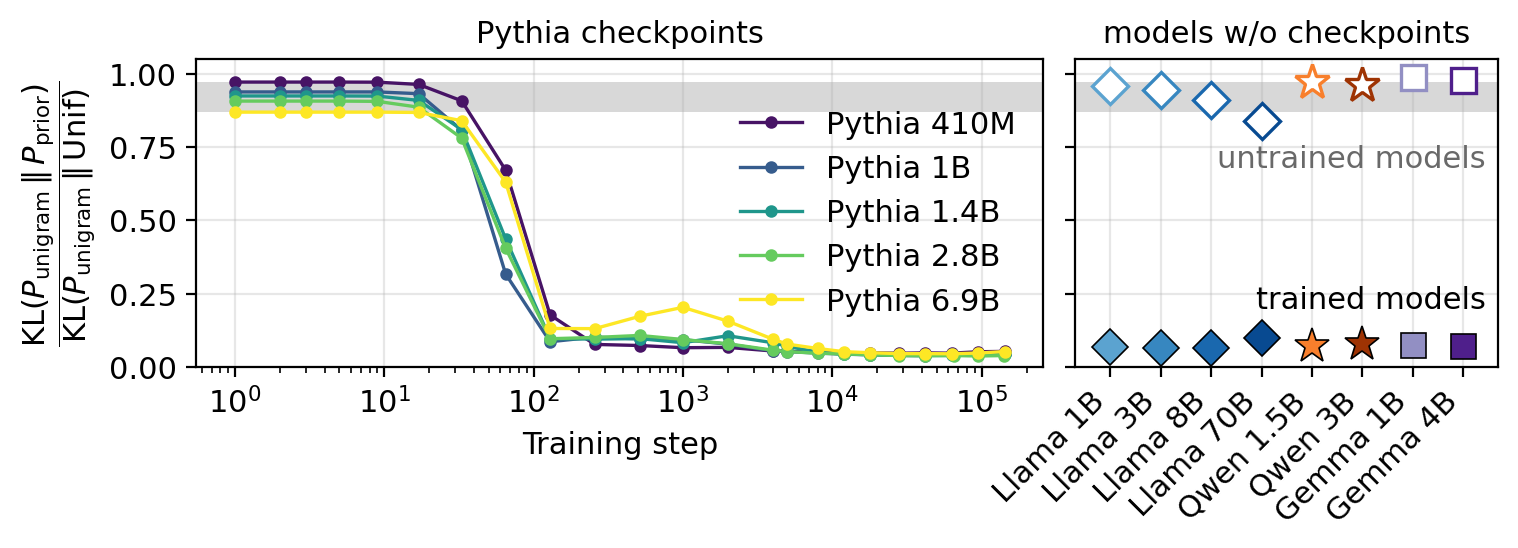

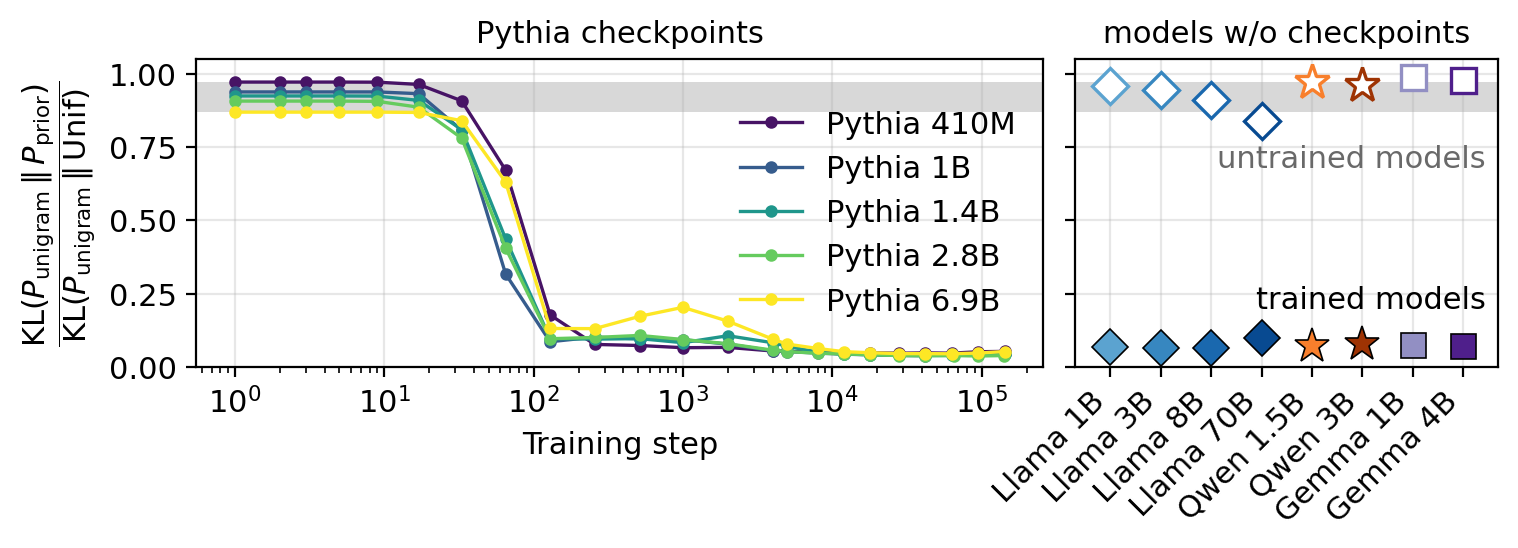

In [14]:
# ── Main-paper figure: prior recovery only ───────────────────────────────────
# Headline metric: nKL is invariant to hidden-space reparameterizations (e.g.
# folding the final norm gain into W), so it compares cleanly across families;
# spectral prominence is frame-dependent and stays in the appendix figures.
from importlib import reload
import training_dynamics_plotter as tdp
reload(tdp)

tdp.plot_prior_recovery(
    loaded,
    nkl_key="nkl",
    outfile="fig3_prior_recovery_main.pdf",
    final_points=final_loaded,
    # yscale="log",  # or "linear"
    yscale="linear"
)

Figure 3. The unigram prior is recovered by a single direction early in training and across model families.

Left: at log-uniformly sampled checkpoints of Pythia 410M, 1B, 1.4B, 2.8B, and 6.9B, the optimal-prior direction $\boldsymbol{d}_{\mathrm{prior}}$ is fit to the unembedding by regressing empirical log-frequencies of Pile tokens. Fit quality is the normalized KL divergence $D_{\mathrm{KL}}(p \,\|\, \hat{p}_{d})\,/\,D_{\mathrm{KL}}(p \,\|\, \mathrm{uniform})$ between the empirical unigram distribution $p$ and the one-dimensional softmax model along $\boldsymbol{d}_{\mathrm{prior}}$ (uniform baseline = 1; log scale, step 0 plotted at 1). Within a few hundred steps the normalized KL drops by an order of magnitude and the curves collapse across model sizes: a single direction suffices to reconstruct the token prior almost as soon as training begins. The gray band, continued across both panels, spans the untrained (step-0) levels of the Pythia suite, from the highest to the lowest.

Right: models without public intermediate checkpoints (Llama 3.2 1B/3B, Llama 3.1 8B, Qwen 2.5 1.5B/3B, Gemma 3 1B/4B), plotted on a shared y-axis. Open markers show an emulated initialization — the output embedding redrawn from each family's initialization scheme, $\mathcal{N}(0, 0.02^2)$ i.i.d. per the HF reference implementations — and filled markers show the released final weights. Every family starts in or near the untrained band and ends at comparably low normalized KL, showing that the one-dimensional encoding of the unigram prior is a universal feature of trained language models rather than an artifact of the Pythia suite.

Within the untrained band (open markers and the Pythia step-0 levels alike), larger models with larger latent dimensions sit at lower normalized KL at initialization. This is expected: random features are automatically orthogonalized in higher dimensions, so it is easier to find a single direction that shatters the data distribution — the regression enjoys more nearly-independent coordinates to fit the log-frequencies with, before any training has occurred.

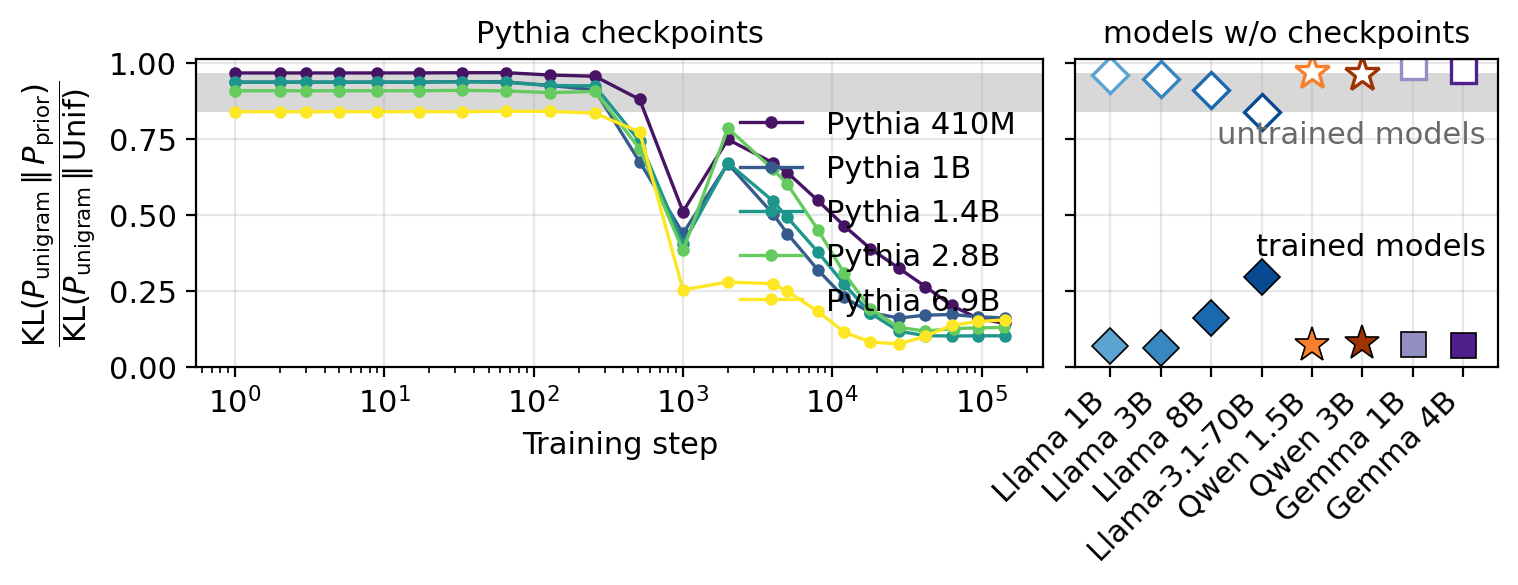

In [8]:
# ── Companion figure: input embeddings (same plotter / styling) ─────────────
from importlib import reload
import training_dynamics_plotter as tdp
reload(tdp)

dyn_cache_dir = DATA_DIR / (
    "training_dynamics_klfine" if KL_fine_fitting else "training_dynamics"
)
_require_in = ("nkl_in", "rank_fraction_in") if plot_rank_fraction else ("nkl_in",)
model_specs = tdp.model_specs_from_figure_models(figure_models)
loaded_in = tdp.load_cached_curves(
    model_specs, dyn_cache_dir, require_keys=_require_in,
)
try:
    final_loaded_in = tdp.load_cached_curves(
        final_specs, final_cache_dir, require_keys=_require_in,
    )
except RuntimeError:
    final_loaded_in = None
if plot_rank_fraction:
    tdp.plot_training_dynamics(
        loaded_in,
        nkl_key="nkl_in",
        rank_key="rank_fraction_in",
        null_key="hm_rank_fraction_in",
        title_suffix=" (input embedding)",
        outfile="fig3_training_dynamics_pythia_inembed.pdf",
        final_points=final_loaded_in,
    )
else:
    # No rank metrics available: show the prior-recovery panel only.
    tdp.plot_prior_recovery(
        loaded_in,
        nkl_key="nkl_in",
        outfile="fig3_prior_recovery_inembed.pdf",
        final_points=final_loaded_in,
        # yscale="log",
        yscale="linear",
    )
